# Video 3.2.1 - Root Mean Squared Error

In [ ]:
#Importing necessary libraries
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

#changing the work directory
os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module3')

#reading the data
data = pd.read_csv('Synergix_data_preprocessed_new.csv')
data.head()

,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,...,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000
0,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,...,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1
1,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,...,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,0
2,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0
3,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,1
4,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0


### Removing Classification Target
- Drops the binary classification column since this is a **regression** problem (predicting actual units sold, not categories).

In [6]:
#drop Units_sold column
data.drop(columns = 'Units_sold>1000', axis = 1, inplace = True)

In [7]:
#check the data
data.head()

,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,...,0.0,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0
1,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,...,0.0,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0
2,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0
3,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0
4,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0


## Good by Bad Ratings

In [8]:
#Storing the ratio in a list named Rating_ratio
Rating_ratio = []
for row in data.values:
    if(row[4]+row[5] == 0):
        if(row[7]+row[8] == 0):
            #If all the ratings are zero then overall rating ratio will also be zero
            Rating_ratio.append(0.0)
        else:
            #If only the numerator(1 and 2 star) ratings are zero then add -99999 to the list temporarily which 
            #will be taken care of in the next part of the code
            Rating_ratio.append(-99999)
    else:
        Rating_ratio.append((int(row[7])+int(row[8]))/(int(row[4])+int(row[5])));

In [9]:
#replacing -99999 with the maximum rating in the list
max_rating = max(Rating_ratio)
for x in range(len(Rating_ratio)):
    if(Rating_ratio[x] == -99999):
        Rating_ratio[x] = max_rating

In [12]:
#adding the column 'Good_By_Bad_Rating' to the dataframe
data['Good_By_Bad_Rating'] = Rating_ratio
#data.head()

In [13]:
#drop the rating columns
data.drop(columns = ['1_Star_Rating', '2_Star_Rating', '3_Star_Rating', '4_Star_Rating', '5_Star_Rating'], inplace = True)

## One-hot Encoding
- Converts categorical *Segment* column (Skincare, Makeup, Hair Care) into binary columns, dropping one to avoid multicollinearity.

In [14]:
#one-hot encoding
data = pd.get_dummies(data, columns = ['Segment'], prefix = 'Segment', drop_first = True)
data.head()

,Page_traffic,Unit_price,Units_sold,Image_Count,Bullet_Count,Title_Count,Description_Length,num_unique_Search_Terms,Organic Search Rank,Num_of_Promotions,...,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Good_By_Bad_Rating,Segment_Makeup,Segment_Skincare
0,5835.0,22.214389,2071,6.0,6.0,89.0,141.0,3.0,3.0,0.0,...,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,21.783626,False,True
1,1881.0,11.870778,681,9.0,8.0,126.0,149.0,13.0,16.0,0.0,...,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,18.397906,False,True
2,2477.0,27.645714,875,10.0,7.0,152.0,186.0,4.0,20.0,0.0,...,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,20.274611,True,False
3,4087.0,16.896848,1396,5.0,7.0,117.0,209.0,7.0,20.0,0.0,...,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,16.171233,True,False
4,1446.0,16.357664,822,0.0,8.0,165.0,158.0,4.0,16.0,0.0,...,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,26.811321,False,False


<h2>Performing Train Test Split</h2>

In [15]:
#Separating the independent and target variables
y = data['Units_sold']
X = data.drop(columns = ['Units_sold'], axis = 1)

In [16]:
#Quick look at the shape of the data
X.shape, y.shape

((19631, 21), (19631,))

In [17]:
#import train test split
from sklearn.model_selection import train_test_split

- Training set: 70% (13,741 samples)
- Test set: 30% (5,890 samples)

In [18]:
#split the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [19]:
#A quick look at the shape of the datasets
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((13741, 21), (5890, 21), (13741,), (5890,))

<h2>Feature Scaling</h2>

In [20]:
#import standard scaler
from sklearn.preprocessing import StandardScaler

In [21]:
#create an instance for StandardScaler
scaler = StandardScaler()

In [22]:
#let's transform the train data
X_train_scaled = scaler.fit_transform(X_train)

In [23]:
X_test_scaled = scaler.transform(X_test)

<h2>KNN Model</h2>

In [24]:
#import the necessary class
from sklearn.neighbors import KNeighborsRegressor

In [25]:
#setting the value k or neighbors at 5
knn_model = KNeighborsRegressor()

In [26]:
#training the knn model with train data
knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [27]:
#making predictions on the same training data
y_train_pred = knn_model.predict(X_train_scaled)

In [28]:
#making predictions on the test data based on the learniing from fitting model on the train data
y_pred = knn_model.predict(X_test_scaled)
y_pred

array([1327. , 1114.8,    0. , ..., 1172.6,  572. , 1743.8], shape=(5890,))

<h2>Evaluating the Model - MAE and RMSE</h2>

In [29]:
#import mse and sqrt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt

In [30]:
#calculate the mae score
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_pred)
print('Train MAE score: ', train_mae)
print('Test MAE score: ', test_mae)

Train MAE score:  146.77272396477696
Test MAE score:  191.74954159592528


In [31]:
#calculate the rmse score
train_rmse = sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = sqrt(mean_squared_error(y_test, y_pred))
print('Train RMSE score: ', train_rmse)
print('Test RMSE score: ', test_rmse)

Train RMSE score:  198.19906162740344
Test RMSE score:  257.053211458683


#### **Observation**
- MAE: On average, predictions are off by ~192 units
- RMSE: Penalizes larger errors more heavily (~257 units)
- Gap between train/test suggests some overfitting
- Lower is better for both metrics

<h1> Video 3.2.2 </h1>


## R² Score
- R² measures **how well your model explains the variance** in the target variable compared to simply using the mean.

In [32]:
#calculate the R2 score for train and test set
from sklearn.metrics import r2_score
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)
print('Train R² score: ', train_r2)
print('Test R² score: ', test_r2)

Train R² score:  0.8066205955219263
Test R² score:  0.6855226236540191


#### Observation
- **Train R²** = 0.81: Model explains 80.66% of variance in training data
- **Test R²** = 0.69: Model explains 68.55% of variance in test data
- **Performance gap**: ~12% difference suggests some overfitting
- Interpretation: Your KNN model is **69% better** than just predicting the mean for new data
    - **Translation**: Your model reduced unexplained variance by **69%**
        - **69%** of variance is explained by your 20 features
        - **31%** of variance is still unexplained (random factors, missing features)

In Short: **R² = 0.69** means your model successfully identified that these 20 features account for 69% of the variability in sales!

R² Score Ranges:
- **1.0** = Perfect predictions
- **0.0** = No better than predicting the mean
- **Negative** = Worse than predicting the mean (indicates a very bad model)

## Adjusted R² - Score

Since the formula for Adjusted r2 requires us to use the number of observations and number of variables, we will use the .shape function to get the 'n' and 'p' values in the formula. 

In [ ]:
train_n = X_train.shape[0]  # Number of training samples (rows)
train_p = X_train.shape[1]  # Number of training features (columns)
test_n = X_test.shape[0]    # Number of test samples
test_p = X_test.shape[1]    # Number of features in test set

In [36]:
#calculate adjusted r2 for train and test data
train_adjusted_r2 = 1 - (1 - train_r2) * (train_n - 1) / (train_n - train_p - 1)
test_adjusted_r2 = 1 - (1 - test_r2) * (test_n - 1) / (test_n - test_p - 1)
print("Train Adjusted R2 score:", train_adjusted_r2)
print("Test Adjusted R2 score:", test_adjusted_r2)

Train Adjusted R2 score: 0.8063245850624148
Test Adjusted R2 score: 0.6843971933705724


#### Key Insights:
1. **Adjusted R² ≤ Regular R²** (always!)
2. **Both remain strong**: Your model still explains ~81% (train) and ~69% (test) of variance after accounting for model complexity
    - which confirms the 20 features are genuinely contributing to predictions, not just inflating R² through overfitting! 

# Choosing the right value of K

The **Problem**: So far, we've been using k=5 (the default), but is that the best choice? Different k values affect model performance!

##### Testing Multiple K Values

In [37]:
#for loop to get accuracy scores for train and test for k values ranging from 1 to 51
train_r2_score = []
test_r2_score = []
for n in range(1,51):
    
    knn_model = KNeighborsRegressor(n_neighbors = n)
    knn_model.fit(X_train_scaled, y_train)
    
    y_train_pred = knn_model.predict(X_train_scaled)
    y_pred = knn_model.predict(X_test_scaled)
    
    train_r2_score.append(r2_score(y_train, y_train_pred))
    test_r2_score.append(r2_score(y_test, y_pred))

- Tests k values from 1 to 50
- For each k, trains a model and calculates R² for both train and test sets
- Stores results in two lists for comparison

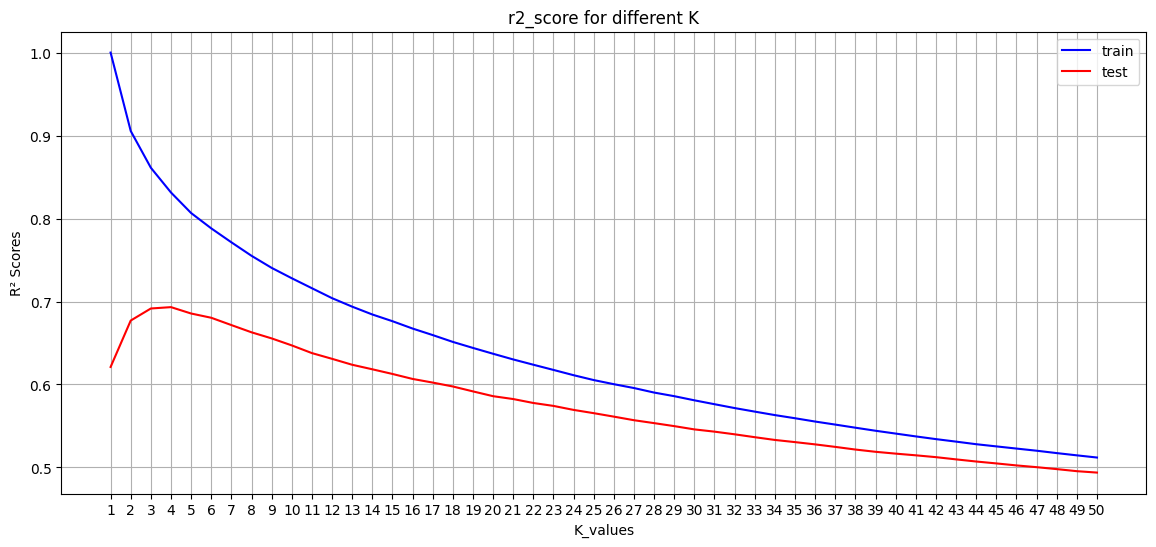

In [38]:
#plot the accuracy scores
plt.figure(figsize = (14,6))
plt.title('r2_score for different K')
plt.plot(np.arange(1, len(train_r2_score)+1), train_r2_score, color = 'blue', label = 'train')
plt.plot(np.arange(1, len(train_r2_score)+1), test_r2_score, color = 'red', label = 'test')
plt.xticks(np.arange(1, len(train_r2_score)+1))
plt.xlabel('K_values')
plt.ylabel('R² Scores')
plt.legend()
plt.grid()
plt.show()



**Creates a graph showing**:
- Blue line: Training R² scores
- Red line: Test R² scores
- X-axis: K values (1-50)
- Y-axis: R² scores

In [39]:
#setting the value k or neighbors at 4
knn_model = KNeighborsRegressor(4)

#training the knn model with train data
knn_model.fit(X_train_scaled, y_train)

#making predictions on the test data based on the learniing from fitting model on the train data
y_pred = knn_model.predict(X_test_scaled)

#calculate the R2 score for test set
test_r2_4k = r2_score(y_test, y_pred)
print('Test R2 score: ', test_r2_4k)

Test R2 score:  0.693208565060998


### Choosing The Best K

**Two business considerations**:
- Option 1: Maximum Performance
    - Choose k=4 → Highest test R² (~0.693)
    - Risk: Model might be slightly overfit  
    
**Use** when: Prediction accuracy is critical
- Option 2: Consistency
    - Choose k=10-15 → Good fit (smaller train-test gap)
    - Slightly lower test R², but more reliable  

**Use** when: Model stability matters more